# <center>Dimensionality reduction with feature selection</center>

# Modules
To enable autoreloading of all modules, it is necessary to install IPython by executing the following command: **pip install ipython**

Example of module importation:
```python
from Modules import data_manipulation_module as dmm
```

| Modul names                   | Description                                             |
|-------------------------------|---------------------------------------------------------|
| data_manipulation_module      | Functions for data manipulation                         |
| nts_classification_module     | Functions for non-time series classification algorithms |
| ts_classification_module      | Functions for time series classification algorithms     |
| validation_and_results_module | Functions for validation and results                    |
| param_tuning_module           | Functions for parameter tuning                          |
| dim_reduction_module          | Functions for dimensionality reduction                  |
| plots_module                  | Functions for plotting                                  |

In [4]:
#autoreload all the modules (no need to rerun the module importation statement to implement the changes)
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## 1. Non-time series classifiers (Full dataset)
### 1.1. Data loading

In [2]:
import glob
import pandas as pd

#beacuse of k-nn
from warnings import simplefilter
simplefilter(action='ignore', category = FutureWarning)

#Numpy version check
import numpy as np
np.__version__
#delete the comment before pip if the version is not 1.21.4
#pip install --upgrade numpy==1.21.4 --user

'1.21.4'

In [5]:
from Modules import data_manipulation_module as dmm

In [6]:
#Saving the files names
NP_csv_files = glob.glob('/tf/notebooks/DatasCSV/NP/*.csv')
KT_csv_files = glob.glob('/tf/notebooks/DatasCSV/KT/*.csv')
SU_csv_files = glob.glob('/tf/notebooks/DatasCSV/SU/*.csv')

NP_csv_files = sorted(NP_csv_files)
KT_csv_files = sorted(KT_csv_files)
SU_csv_files = sorted(SU_csv_files)

In [7]:
NP_df_list = dmm.Loading_data(NP_csv_files, ";", None)
KT_df_list = dmm.Loading_data(KT_csv_files, ";", None)
SU_df_list = dmm.Loading_data(SU_csv_files, ";", None)

In [8]:
NP_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Needle_Passing.txt', " ", None)
KT_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Knot_Tying.txt', " ", None)
SU_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Suturing.txt', " ", None)

In [9]:
NP_class_binary = NP_class.copy()
KT_class_binary = KT_class.copy()
SU_class_binary = SU_class.copy()

NP_class_multi = NP_class.copy()
KT_class_multi = KT_class.copy()
SU_class_multi = SU_class.copy()

NP_class_binary["GRS"] = np.where(NP_class["GRS"] < 16, 0, 1)
KT_class_binary["GRS"] = np.where(KT_class["GRS"] < 16, 0, 1)
SU_class_binary["GRS"] = np.where(SU_class["GRS"] < 16, 0, 1)

NP_class_multi["GRS"] = NP_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))
KT_class_multi["GRS"] = KT_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))
SU_class_multi["GRS"] = SU_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))

### 1.2. ApEn

In [72]:
#Copying the header from the previous dataframes and using this dataframe to create the new dataframes for storing non-time series datas
feature_names = NP_df_list[0].columns
    
NP_ApEn = pd.DataFrame(columns = feature_names)
KT_ApEn = pd.DataFrame(columns = feature_names)
SU_ApEn = pd.DataFrame(columns = feature_names)

In [73]:
#This may require a considerable amount of time to execute.
#Approximate_entropy(df_list, return_ApEn)
NP_ApEn = dmm.Approximate_entropy(NP_df_list, NP_ApEn)
KT_ApEn = dmm.Approximate_entropy(KT_df_list, KT_ApEn)
SU_ApEn = dmm.Approximate_entropy(SU_df_list, SU_ApEn)

In [74]:
#Appending the target variables to the data
#Target_append(df_class, return_ApEn, class_column_name)
NP_ApEn_binary = NP_ApEn.copy()
KT_ApEn_binary = KT_ApEn.copy()
SU_ApEn_binary = SU_ApEn.copy()

NP_ApEn_multi = NP_ApEn.copy()
KT_ApEn_multi = KT_ApEn.copy()
SU_ApEn_multi = SU_ApEn.copy()

NP_ApEn_binary = dmm.Target_append(NP_class_binary, NP_ApEn_binary, "GRS")
KT_ApEn_binary = dmm.Target_append(KT_class_binary, KT_ApEn_binary, "GRS")
SU_ApEn_binary = dmm.Target_append(SU_class_binary, SU_ApEn_binary, "GRS")

NP_ApEn_multi = dmm.Target_append(NP_class_multi, NP_ApEn_multi, "GRS")
KT_ApEn_multi = dmm.Target_append(KT_class_multi, KT_ApEn_multi, "GRS")
SU_ApEn_multi = dmm.Target_append(SU_class_multi, SU_ApEn_multi, "GRS")

In [75]:
#Features and target variable
NP_X_ApEn, NP_Y_ApEn_binary = dmm.Features_target(NP_ApEn_binary)
KT_X_ApEn, KT_Y_ApEn_binary = dmm.Features_target(KT_ApEn_binary)
SU_X_ApEn, SU_Y_ApEn_binary = dmm.Features_target(SU_ApEn_binary)

#Multiclass version
NP_X_ApEn, NP_Y_ApEn_multi = dmm.Features_target(NP_ApEn_multi)
KT_X_ApEn, KT_Y_ApEn_multi = dmm.Features_target(KT_ApEn_multi)
SU_X_ApEn, SU_Y_ApEn_multi = dmm.Features_target(SU_ApEn_multi)

---
## 2. Non-time series classifiers (Gestures)
### 2.1. Data loading

In [10]:
NP_gesture_files = glob.glob('/tf/notebooks/Gestures/NP/*.csv')
KT_gesture_files = glob.glob('/tf/notebooks/Gestures/KT/*.csv')
SU_gesture_files = glob.glob('/tf/notebooks/Gestures/SU/*.csv')

NP_gesture_files = sorted(NP_gesture_files)
KT_gesture_files = sorted(KT_gesture_files)
SU_gesture_files = sorted(SU_gesture_files)

In [11]:
NP_gesture_df_list = dmm.Loading_data(NP_gesture_files, ";", None)
KT_gesture_df_list = dmm.Loading_data(KT_gesture_files, ";", None)
SU_gesture_df_list = dmm.Loading_data(SU_gesture_files, ";", None)

### 2.2. Dataset division by gestures

In [15]:
Needle_Passing_gestures = [1, 2, 3, 4, 5, 6, 8, 11]
Knot_Tying_gestures = [1 , 11 , 12 , 13 , 14 , 15]
Suturing_gestures = [1, 2, 3, 4, 5, 6, 8, 9, 10, 11]

number_of_gestures = 15
feature_names = NP_df_list[0].columns

In [16]:
#Gestures_data_splitting(number_of_gestures, feature_names, gestures, gesture_df_list, df_list)  
NP_gestures = dmm.Gestures_data_splitting(number_of_gestures, feature_names, Needle_Passing_gestures, NP_gesture_df_list, NP_df_list)
KT_gestures = dmm.Gestures_data_splitting(number_of_gestures, feature_names, Knot_Tying_gestures, KT_gesture_df_list, KT_df_list)
SU_gestures = dmm.Gestures_data_splitting(number_of_gestures, feature_names, Suturing_gestures, SU_gesture_df_list, SU_df_list)

In [19]:
NP_gestures_ApEn_binary = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, NP_gestures, feature_names, NP_class_binary, 2)
KT_gestures_ApEn_binary = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, KT_gestures, feature_names, KT_class_binary, 2)
SU_gestures_ApEn_binary = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, SU_gestures, feature_names, SU_class_binary, 2)

NP_gestures_ApEn_multi = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, NP_gestures, feature_names, NP_class_multi, 2)
KT_gestures_ApEn_multi = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, KT_gestures, feature_names, KT_class_multi, 2)
SU_gestures_ApEn_multi = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, SU_gestures, feature_names, SU_class_multi, 2)

In [20]:
#Gestures_features_target(task_gestures, gestures_idxs, minimum_rows)
print("Binary:")
NP_gestures_X_ApEn, NP_gestures_Y_ApEn_binary, Needle_Passing_gestures_binary = dmm.Gestures_features_target(NP_gestures_ApEn_binary, Needle_Passing_gestures, 1)
KT_gestures_X_ApEn, KT_gestures_Y_ApEn_binary, Knot_Tying_gestures_binary = dmm.Gestures_features_target(KT_gestures_ApEn_binary, Knot_Tying_gestures, 1)
SU_gestures_X_ApEn, SU_gestures_Y_ApEn_binary, Suturing_gestures_binary = dmm.Gestures_features_target(SU_gestures_ApEn_binary, Suturing_gestures, 1)

print("\nMulti:")
NP_gestures_X_ApEn, NP_gestures_Y_ApEn_multi, Needle_Passing_gestures_multi = dmm.Gestures_features_target(NP_gestures_ApEn_multi, Needle_Passing_gestures, 1)
KT_gestures_X_ApEn, KT_gestures_Y_ApEn_multi, Knot_Tying_gestures_multi = dmm.Gestures_features_target(KT_gestures_ApEn_multi, Knot_Tying_gestures, 1)
SU_gestures_X_ApEn, SU_gestures_Y_ApEn_multi, Suturing_gestures_multi = dmm.Gestures_features_target(SU_gestures_ApEn_multi, Suturing_gestures, 1)

Binary:
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 11]
Final gestures for the task: [1, 11, 12, 13, 14, 15]
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 9, 10, 11]

Multi:
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 11]
Final gestures for the task: [1, 11, 12, 13, 14, 15]
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 9, 10, 11]


---
## 3. Dimensionality reduction with feature selection before the hyperparameter tuning (non-time series classifier)

In [20]:
%set_env TF_ENABLE_ONEDNN_OPTS=0

env: TF_ENABLE_ONEDNN_OPTS=0


In [21]:
#Querying the number of CPUs.
import os
n_cpu = os.cpu_count()
print(n_cpu)

60


In [68]:
from Modules import dim_reduction_module as drm
from Modules import plots_module as pm

from sklearn.feature_selection import mutual_info_classif as MIC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import LeaveOneOut

In [69]:
models = {
        'decision_tree': {
            'model': DecisionTreeClassifier(),
            'params': {
                'criterion':  ['gini', 'entropy'],
                'max_depth':  [None, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                'max_features': [None, 'sqrt', 'log2', 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
                'splitter': ['best', 'random'],
                'random_state': [0]
                     }
        },
        'k-NN': {
            'model': KNeighborsClassifier(),
            'params': {
                #+1: to included the last value in the range.
                'n_neighbors' : range(1, 5),
                'weights' : ['uniform', 'distance'],
                'metric' : ['euclidean', 'manhattan', 'minkowski']
                      }
        },
        'logistic_regression': {
            'model': LogisticRegression(),
            'params': {
                #Delete the comment before multi_class for multiclassification
                #'multi_class': ['ovr'], #For multiclass
                'penalty' : ["l1", "l2"],
                'solver' : ["newton-cg", "lbfgs", "liblinear", "sag", "saga"],
                'C':  [0.1, 0.5, 1, 5, 10, 50,  100, 500, 1000],
                #The maximum iteration value had to be increased (to 10000) due to convergence warnings.
                'max_iter': [10000],
                'random_state' : [0]
                    }
        },
        'SVM': {
            'model': svm.SVC(),
            'params': {
                #Delete the comment before multi_class for multiclassification
                #'decision_function_shape': ['ovo'], #For multiclass
                'C': [1000, 500, 100, 50, 10, 5, 1, 0.5, 0.1],
                'kernel' : ['poly', 'rbf', 'sigmoid', 'linear'],
                'gamma': ['auto', 'scale', 1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001],
                'random_state' : [0]
                       }
        
         }
}

In [18]:
test_size = [0.1, 0.2, 0.3, 0.4]

In [26]:
#MIC_dimRed_and_hyperparameter_tuning(models, metric, X, Y, test_sizes, cv, MIC_step, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
NP_score_dimRed, NP_estimator_dimRed, NP_feature_dimRed, NP_threshold_dimRed = drm.MIC_dimRed_and_hyperparameter_tuning(models, "f1_macro", NP_X_ApEn, NP_Y_ApEn_binary, [0.3], 3, 0.01, \
                                                                                                                        feature_names, "No", True, True, -1)

Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 12


,Model,Validation score,Test score,Parameter,Features,MIC_threshold
0,decision_tree,0.888889,0.861538,"DecisionTreeClassifier(max_features=0.7, random_state=0, splitter='random')","[10, 16, 17, 35, 36, 43, 54, 55, 67, 71]",0.09
1,k-NN,0.925926,0.861538,"KNeighborsClassifier(metric='euclidean', n_neighbors=7)","[10, 16, 17, 35, 36, 43, 54, 55, 67, 71]",0.09
2,logistic_regression,0.942857,0.861538,"LogisticRegression(C=100, max_iter=10000, penalty='l1', random_state=0,\n solver='liblinear')","[16, 35, 36, 54, 55]",0.12
3,SVM,0.942857,0.750000,"SVC(C=1000, random_state=0)","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07


In [27]:
#Multiple_cv_MIC_dimRed_and_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, MIC_step, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
NP_scores_dimRed, NP_estimators_dimRed, NP_features_dimRed, NP_thresholds_dimRed, NP_cvs_dimRed = \
    drm.Multiple_cv_MIC_dimRed_and_hyperparameter_tuning(2, 6, models, "f1_macro", NP_X_ApEn, NP_Y_ApEn_binary, [0.3], 0.01, feature_names, "No", True, True, -1)

CV: 2
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9


,Model,Validation score,Test score,Parameter,Features,MIC_threshold
0,decision_tree,0.683036,0.678571,"DecisionTreeClassifier(max_features=0.3, random_state=0)","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 5...",0.00
1,k-NN,0.941558,0.861538,"KNeighborsClassifier(metric='manhattan', n_neighbors=1)","[16, 35, 36, 54, 55, 71]",0.11
2,logistic_regression,0.874892,0.861538,"LogisticRegression(C=1000, max_iter=10000, penalty='l1', random_state=0,\n solver='liblinear')","[16, 35, 36, 54, 55]",0.12
3,SVM,0.880952,0.750000,"SVC(C=1000, gamma='auto', kernel='linear', random_state=0)","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07


CV: 3
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 12


,Model,Validation score,Test score,Parameter,Features,MIC_threshold
0,decision_tree,0.888889,0.861538,"DecisionTreeClassifier(max_features=0.7, random_state=0, splitter='random')","[10, 16, 17, 35, 36, 43, 54, 55, 67, 71]",0.09
1,k-NN,0.925926,0.861538,"KNeighborsClassifier(metric='euclidean', n_neighbors=7)","[10, 16, 17, 35, 36, 43, 54, 55, 67, 71]",0.09
2,logistic_regression,0.942857,0.861538,"LogisticRegression(C=100, max_iter=10000, penalty='l1', random_state=0,\n solver='liblinear')","[16, 35, 36, 54, 55]",0.12
3,SVM,0.942857,0.750000,"SVC(C=1000, random_state=0)","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07


CV: 4
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 14


,Model,Validation score,Test score,Parameter,Features,MIC_threshold
0,decision_tree,0.875000,0.861538,"DecisionTreeClassifier(max_features=0.7, random_state=0, splitter='random')","[10, 16, 17, 35, 36, 43, 54, 55, 67, 71]",0.09
1,k-NN,0.933333,0.750000,"KNeighborsClassifier(metric='euclidean', n_neighbors=4, weights='distance')","[16, 35, 36, 54, 55]",0.12
2,logistic_regression,0.873810,0.750000,"LogisticRegression(C=50, max_iter=10000, random_state=0, solver='newton-cg')","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07
3,SVM,0.933333,0.750000,"SVC(C=1000, gamma=1, random_state=0)","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07


CV: 5
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15


,Model,Validation score,Test score,Parameter,Features,MIC_threshold
0,decision_tree,0.933333,0.678571,DecisionTreeClassifier(random_state=0),"[4, 6, 8, 10, 11, 12, 13, 16, 17, 18, 25, 26, 28, 30, 35, 36, 37, 43, 44, 45, 47, 49, 54, 55, 58, 61, 67, 70, 71, 74]",0.02
1,k-NN,0.826667,0.861538,"KNeighborsClassifier(metric='euclidean', n_neighbors=9, weights='distance')","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07
2,logistic_regression,0.819048,0.750000,"LogisticRegression(C=50, max_iter=10000, random_state=0, solver='newton-cg')","[10, 16, 17, 35, 36, 43, 54, 55, 71]",0.10
3,SVM,0.933333,0.750000,"SVC(C=1000, gamma=1, random_state=0)","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07


CV: 6
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15


,Model,Validation score,Test score,Parameter,Features,MIC_threshold
0,decision_tree,0.944444,0.678571,DecisionTreeClassifier(random_state=0),"[4, 6, 8, 10, 11, 12, 13, 16, 17, 18, 25, 26, 28, 30, 35, 36, 37, 43, 44, 45, 47, 49, 54, 55, 58, 61, 67, 70, 71, 74]",0.02
1,k-NN,0.844444,0.861538,"KNeighborsClassifier(metric='euclidean', n_neighbors=9, weights='distance')","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07
2,logistic_regression,0.844444,0.750000,"LogisticRegression(C=50, max_iter=10000, random_state=0, solver='newton-cg')","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07
3,SVM,0.944444,0.750000,"SVC(C=1000, gamma=1, random_state=0)","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07


In [28]:
dmm.Best_dimRed_hyperparameter_tuning_scores(NP_scores_dimRed, NP_estimators_dimRed, NP_features_dimRed, NP_thresholds_dimRed, NP_cvs_dimRed, [0.3], ['Decision Tree', 'k-NN', 'Logistic Regression', 'SVM'])

Test size: 0.3


,Classification algorithm,Best test score,Best estimator,Features,MIC_threshold,Best cv
0,Decision Tree,0.861538,"DecisionTreeClassifier(max_features=0.7, random_state=0, splitter='random')","[10, 16, 17, 35, 36, 43, 54, 55, 67, 71]",0.09,3
1,k-NN,0.861538,"KNeighborsClassifier(metric='manhattan', n_neighbors=1)","[16, 35, 36, 54, 55, 71]",0.11,2
2,Logistic Regression,0.861538,"LogisticRegression(C=1000, max_iter=10000, penalty='l1', random_state=0,\n solver='liblinear')","[16, 35, 36, 54, 55]",0.12,2
3,SVM,0.750000,"SVC(C=1000, gamma='auto', kernel='linear', random_state=0)","[4, 10, 16, 17, 18, 30, 35, 36, 43, 44, 49, 54, 55, 61, 67, 71, 74]",0.07,2


### Diagrams
#### linechart

In [363]:
s, e, f, t, c = drm.Multiple_cv_MIC_dimRed_and_hyperparameter_tuning(2, 6, models, "f1_macro", \
                                                                     NP_X_ApEn, NP_Y_ApEn_binary, [0.3], 0.01, \
                                                                     feature_names, "No", True, False, -1)

CV: 2
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9
CV: 3
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 12
CV: 4
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 14
CV: 5
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15
CV: 6
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15


In [365]:
s

[[[0.6785714285714286], [0.8615384615384616], [0.8615384615384616], [0.75]],
 [[0.8615384615384616], [0.8615384615384616], [0.8615384615384616], [0.75]],
 [[0.8615384615384616], [0.75], [0.75], [0.75]],
 [[0.6785714285714286], [0.8615384615384616], [0.75], [0.75]],
 [[0.6785714285714286], [0.8615384615384616], [0.75], [0.75]]]

In [364]:
#Multiple_cv_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
NP_scores, NP_estimators, NP_cvs = ptm.Multiple_cv_hyperparameter_tuning(2, 6, models, "f1_macro", \
                                                                         NP_X_ApEn, NP_Y_ApEn_binary, \
                                                                         [0.3], feature_names, "No", \
                                                                         True, False, -1)

CV: 2
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9
CV: 3
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 12
CV: 4
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 14
CV: 5
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15
CV: 6
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15


In [373]:
NP_scores

[[[0.6785714285714286],
  [0.6785714285714286],
  [0.5846153846153845],
  [0.5846153846153845]],
 [[0.5846153846153845],
  [0.6785714285714286],
  [0.6785714285714286],
  [0.5846153846153845]],
 [[0.6493506493506493],
  [0.6785714285714286],
  [0.6785714285714286],
  [0.5846153846153845]],
 [[0.6493506493506493],
  [0.6785714285714286],
  [0.5846153846153845],
  [0.5846153846153845]],
 [[0.6493506493506493],
  [0.6785714285714286],
  [0.5846153846153845],
  [0.5846153846153845]]]

In [413]:
#Best_param_tuning_accuracies(acc, estimator, cvs, test_size, class_alg)
NP_score = dmm.Best_hyperparameter_tuning_scores(NP_scores, NP_estimators, NP_cvs, [0.3], ['Decision Tree', 'k-NN', 'Logistic Regression', 'SVM'])

Test size: 0.3


,Classification algorithm,Best test score,Best estimator,Best cv
0,Decision Tree,0.678571,"DecisionTreeClassifier(max_features=0.3, random_state=0)",2
1,k-NN,0.678571,"KNeighborsClassifier(metric='euclidean', n_neighbors=1)",2
2,Logistic Regression,0.678571,"LogisticRegression(C=50, max_iter=10000, random_state=0, solver='newton-cg')",3
3,SVM,0.584615,"SVC(C=1000, decision_function_shape='ovo', gamma=0.05, kernel='sigmoid',\n random_state=0)",2


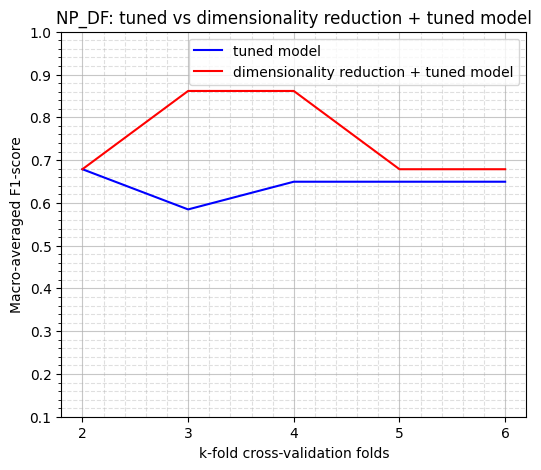

In [415]:
#def Line_chart(scores1, scores2, k_values, classifier_index, fig_size, title, plot_labels, colors, ylabel)
pm.Line_chart(NP_scores, s, range(2, 6+1, 1), 0, (6,5), "NP_DF: tuned vs dimensionality reduction + tuned model", \
              ["tuned model", "dimensionality reduction + tuned model"], ["blue", "red"], "Macro-averaged F1-score")

---
## 4. Time series k-NN (Full dataset)
### 4.1. Data transformation

In [12]:
TS_NP_df_list_min_len = dmm.TS_df_truncate_to_min_len(NP_df_list)
TS_KT_df_list_min_len = dmm.TS_df_truncate_to_min_len(KT_df_list)
TS_SU_df_list_min_len = dmm.TS_df_truncate_to_min_len(SU_df_list)

The minimum length: 1787
The minimum length: 920
The minimum length: 1779


In [13]:
#TS_Y(df_class, column_index)
TS_NP_Y_binary = dmm.TS_Y(NP_class_binary, 2)
TS_KT_Y_binary = dmm.TS_Y(KT_class_binary, 2)
TS_SU_Y_binary = dmm.TS_Y(SU_class_binary, 2)

#Multiclass version
TS_NP_Y_multi = dmm.TS_Y(NP_class_multi, 2)
TS_KT_Y_multi = dmm.TS_Y(KT_class_multi, 2)
TS_SU_Y_multi = dmm.TS_Y(SU_class_multi, 2)

---
## 5. Time series k-NN (Gestures)
### 5.1. Data transformation

In [17]:
TS_NP_gestures_df_list_min_len = dmm.TS_gestures_df_truncate_to_min_len(NP_gestures)
TS_KT_gestures_df_list_min_len = dmm.TS_gestures_df_truncate_to_min_len(KT_gestures)
TS_SU_gestures_df_list_min_len = dmm.TS_gestures_df_truncate_to_min_len(SU_gestures)

In [420]:
TS_NP_gestures_X_min_len, TS_NP_gestures_Y_binary, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_min_len, NP_class_binary, 2)
TS_KT_gestures_X_min_len, TS_KT_gestures_Y_binary, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_min_len, KT_class_binary, 2)
TS_SU_gestures_X_min_len, TS_SU_gestures_Y_binary, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_min_len, SU_class_binary, 2)

TS_NP_gestures_X_min_len, TS_NP_gestures_Y_multi, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_min_len, NP_class_multi, 2)
TS_KT_gestures_X_min_len, TS_KT_gestures_Y_multi, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_min_len, KT_class_multi, 2)
TS_SU_gestures_X_min_len, TS_SU_gestures_Y_multi, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_min_len, SU_class_multi, 2)

---
# 6. Dimensionality reduction with PCA 

In [23]:
from sktime.classification.distance_based import KNeighborsTimeSeriesClassifier 

In [24]:
TS_model = {
        'Time_series_kNN': {
            'model': KNeighborsTimeSeriesClassifier(distance="dtw"), #n_jobs only makes it quicker a little bit
            'params': {
                #+1: to included the last value in the range.
                'n_neighbors' : range(1, 5),
                'weights' : ['uniform', 'distance']
                      }
               }
           }

In [25]:
test_size = [0.1, 0.2, 0.3, 0.4]

In [143]:
#TS_PCA_dimRed_and_hyperparameter_tuning(models, metric, X, Y, test_sizes, cv, component, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
score, estimator, features = drm.TS_PCA_dimRed_and_hyperparameter_tuning(TS_model, "f1_macro", TS_NP_df_list_min_len, TS_NP_Y_binary, test_size, 2, 0.99, feature_names, "No", True, True, -1)

Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 12


,Model,Validation score,Test score,Parameter,Features
0,Time_series_kNN,0.793056,1.0,KNeighborsTimeSeriesClassifier(n_neighbors=3),"[3, 4, 5, 6, 7, 8, 15, 16, 17, 18, 23, 24, 27, 28, 30, 34, 35, 36, 37, 43, 53, 54, 55, 60, 61, 63, 64, 66, 72, 73, 74]"




Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 11


,Model,Validation score,Test score,Parameter,Features
0,Time_series_kNN,0.811966,0.777778,KNeighborsTimeSeriesClassifier(n_neighbors=3),"[3, 6, 7, 8, 15, 16, 17, 18, 23, 24, 27, 29, 30, 34, 35, 36, 37, 41, 46, 53, 54, 55, 60, 61, 64, 66, 67, 72, 73, 74, 75]"




Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9


,Model,Validation score,Test score,Parameter,Features
0,Time_series_kNN,0.820055,0.584615,KNeighborsTimeSeriesClassifier(n_neighbors=4),"[3, 6, 7, 8, 11, 15, 16, 17, 18, 23, 30, 34, 35, 36, 37, 41, 42, 46, 53, 54, 55, 60, 61, 64, 66, 67, 68, 72, 73, 74, 75]"




Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 8


,Model,Validation score,Test score,Parameter,Features
0,Time_series_kNN,0.873016,0.4375,KNeighborsTimeSeriesClassifier(),"[3, 4, 6, 7, 8, 15, 16, 17, 18, 23, 24, 34, 35, 36, 37, 41, 43, 46, 53, 54, 55, 60, 61, 64, 66, 67, 68, 72, 73, 74, 75]"


In [144]:
#TS_Multiple_cv_PCA_dimRed_and_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, component, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
s, e, f, c = drm.TS_Multiple_cv_PCA_dimRed_and_hyperparameter_tuning(2, 6, TS_model, "f1_macro", TS_NP_df_list_min_len, TS_NP_Y_binary, [0.3], 0.99, feature_names, "No", True, False, -1)

CV: 2
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9
CV: 3
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 12
CV: 4
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 14
CV: 5
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15
CV: 6
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15


In [145]:
dmm.Best_PCA_dimRed_hyperparameter_tuning_scores(s, e, f, c, [0.3], ['Time series k-NN'])

Test size: 0.3


,Classification algorithm,Best test score,Best estimator,Features,Best cv
0,Time series k-NN,0.75,KNeighborsTimeSeriesClassifier(n_neighbors=7),"[3, 6, 7, 8, 11, 15, 16, 17, 18, 23, 30, 34, 35, 36, 37, 41, 42, 46, 53, 54, 55, 60, 61, 64, 66, 67, 68, 72, 73, 74, 75]",4


### Results checking

In [147]:
x_tr, x_te, y_tr, y_te = dmm.Train_test(TS_NP_df_list_min_len, TS_NP_Y_binary, 0.3)

X_tr = []
X_te = []
for i in range(len(x_tr)):
    X_tr.append(x_tr[i].iloc[:, [3, 6, 7, 8, 11, 15, 16, 17, 18, 23, 30, 34, 35, 36, 37, 41, 42, 46, 53, 54, 55, 60, 61, 64, 66, 67, 68, 72, 73, 74, 75]])
    
for i in range(len(x_te)):
    X_te.append(x_te[i].iloc[:, [3, 6, 7, 8, 11, 15, 16, 17, 18, 23, 30, 34, 35, 36, 37, 41, 42, 46, 53, 54, 55, 60, 61, 64, 66, 67, 68, 72, 73, 74, 75]])
    
x_tr, x_te = dmm.TS_kNN_DTW_transform(X_tr, X_te)

In [148]:
from Modules import ts_classification_algorithms_module as ts_cam
TS_kNN_DTW_model_binary = ts_cam.TS_kNN_DTW(7, "uniform")

from Modules import validation_and_results_module as vrm
vrm.Model_classification_report(TS_kNN_DTW_model_binary, x_tr, x_te, y_tr, y_te)

Actual classes: [0 1 0 1 0 0 0 0 1], Predicted classes: [0 1 0 0 0 0 1 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.83      0.83      0.83         6
           1       0.67      0.67      0.67         3

    accuracy                           0.78         9
   macro avg       0.75      0.75      0.75         9
weighted avg       0.78      0.78      0.78         9

